# Experimental mixed-volume oracles: my cube-and-ball implementation
**Sourav Roy**

**Research date supplied by me:** 30 March 2026.  
**Notebook implementation assembled and tested:** 9 October 2026.

I use the research date to identify the earlier research context. I do not use it as a claim that this notebook, its code, or these numerical results existed on that date. A later GitHub upload also does not establish an earlier creation date.

I use this notebook to explore the algorithms in my thesis numerically. I distinguish the mathematical model from my current numerical implementation. I have not certified the thesis's ideal-oracle guarantees in this notebook.

I run the cells from top to bottom. I choose the dimension N, number of B3 samples M, lambda, target index K, and the other sampling settings in the first code cell. I can run the cube-and-ball experiment in dimension 3, 4, 10, or another positive integer dimension. Larger choices can take longer. I need NumPy and Matplotlib; I do not run an installation command here. On my earlier setup I can select the `Python (convex-walks)` kernel.

I use the centered cube of side length 2:

$$
P=[-1,1]^n,\qquad B=B_2^n,\qquad K_\lambda=P+\lambda B,\qquad \lambda\geq0.
$$

I therefore have an inner radius 1 and outer radius equal to the square root of n. My use of “unit cube” means this centered cube, not the side-length-1 cube.

$$
\operatorname{Vol}(K_\lambda)=\sum_{i=0}^{n}\binom{n}{i}M_i\lambda^i,
\qquad M_i=V(P[n-i],B[i]).
$$

$$
p_i(\lambda)=\frac{\binom{n}{i}M_i\lambda^i}{\operatorname{Vol}(K_\lambda)}.
$$

I use codimension as the component label. I do not claim that the first point selected on a random chord is a uniform point in the whole body.

If I change my settings, I restart the kernel and run all cells again so function defaults and outputs use the new choices. I enter every setting explicitly. Saved example outputs are labeled with the settings used; my next run replaces them.

I use my chosen N consistently in all experiment cells. My implementation limitations below describe the gap from ideal-oracle access; they are not a review of the thesis proofs.

## How I run and share this notebook
I open this .ipynb file in Jupyter or VS Code's notebook editor. On my Mac, I select the Python (convex-walks) kernel, restart it, and run the cells from top to bottom. I complete all input prompts in the first code cell. If I see NameError messages after an earlier cell fails, I fix the first error and restart rather than continue through the later cells.

For a small execution check I can choose N=3, M=100, lambda=1, K=2, samples=200, burn-in=100, spacing=1, threshold=0.05, seed=2026, and tolerance=1e-9. These are suggestions, not required answers or accuracy guarantees. A blank numerical answer is not accepted; I enter my own value.

I can upload this .ipynb file directly to GitHub. Its Markdown explanations, code, saved numerical outputs, and chart images travel together. I save my notebook after running it so the uploaded file contains my outputs. GitHub displays a notebook preview; I execute it in Jupyter or VS Code.


The saved execution check uses N=3, M=100, lambda=1, K=2, samples=200, burn-in=100, spacing=1, threshold=0.05, seed=2026, tolerance=1e-9. I do not present this short check as a mixing or accuracy certificate.

Before each input, I give a one-line explanation of what it controls. My B3 sample count controls the standalone frequency experiment; the separate per-phase/query budget controls B1 and Algorithms 2–3. If I change my settings, I restart and run all cells again.

## What I implement and what my ideal oracles assume

| Item | Thesis role | Implementation here | Remaining limitation |
|---|---|---|---|
| B1 | Approximate volume oracle | Multiphase volume ratios from hit-and-run | No proven mixing or error budget |
| Algorithm 1 / B2 | Uniform point → exact projection → label | Continuing cube walk + clipping projection | Finite chain; floating-point boundary ambiguity |
| B3 | Estimate label distribution | Frequencies from one continuing chain | Correlated observations; no IID Hoeffding certificate |
| Algorithm 2 | Noisy search for a useful lambda | Geometric midpoint and empirical threshold margin | Heuristic bracket/margin; may be inconclusive |
| Algorithm 3 | Recover chosen mixed volume | Combine B1 and fresh B3 after search | Inherits all estimation errors |

I treat ideal B2 access as an assumption about sampling and exact component output. For my cube, I can calculate the projection explicitly. What I have not supplied is a proof that my finite walk gives the required uniform distribution, or that floating-point decisions provide exact labels in every case. I do not conclude that such an oracle is impossible; I distinguish assumed ideal access from what I have implemented.

This notebook does not accept an arbitrary inequality matrix. Extending it to arbitrary polytopes requires replacing membership/projection, validating the body, and revisiting precision and mixing.

In [1]:
import math
import time
import sys
import numpy as np

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("I choose my settings below; there are no mandatory preset answers.")

def read_int(label, minimum=0, maximum=None):
    while True:
        try:
            value = int(input(label + ": ").strip())
            if value < minimum or (maximum is not None and value > maximum):
                raise ValueError()
            return value
        except ValueError:
            upper = f" and <= {maximum}" if maximum is not None else ""
            print(f"Enter an integer >= {minimum}{upper}.")


def read_float(label, minimum=0.0, strict_min=False, maximum=None):
    while True:
        try:
            value = float(input(label + ": ").strip())
            if not np.isfinite(value):
                raise ValueError()
            if value < minimum or (strict_min and value == minimum):
                raise ValueError()
            if maximum is not None and value >= maximum:
                raise ValueError()
            return value
        except ValueError:
            bound = ">" if strict_min else ">="
            upper = f" and < {maximum}" if maximum is not None else ""
            print(f"Enter a finite number {bound} {minimum}{upper}.")



print("Dimension: I choose how many coordinates each point has; for example, 3 means three-dimensional space.")
N = read_int("Choose dimension N (positive integer)", 1)
print("B3 sample count: I choose how many point labels to record when estimating the component probabilities.")
M = read_int("Choose number M of recorded B3 labels", 1)
print("Lambda: I choose the radius of the ball added to the cube; zero leaves the cube unchanged.")
LAMBDA = read_float("Choose nonnegative lambda for standalone B1/B2/B3")
print("Target component: I choose the mixed-volume index to estimate; in dimension 3, labels 0, 1, 2, 3 mean cube interior, face, edge, and vertex projection regions.")
K = read_int(f"Choose target index K (0 through {N})", 0, N)
print("Samples per phase/query: I choose how many observations each volume phase and initial search query uses; this is separate from the B3 sample count above.")
SAMPLES = read_int("Choose samples per B1 phase / initial search query", 1)
print("Burn-in: I choose how many initial walk moves to discard before recording samples; more moves cost time and do not by themselves prove mixing.")
BURN_IN = read_int("Choose burn-in transitions", 0)
print("Spacing: I choose how many walk moves occur before each recorded point; extra moves may reduce correlation but do not guarantee independence.")
SPACING = read_int("Choose transitions between recorded samples", 1)
print("Search threshold: I choose the target component probability level that the experimental lambda search tries to exceed; this is not an error tolerance.")
THRESHOLD = read_float("Choose search threshold (strictly between 0 and 1)",
                       0, strict_min=True, maximum=1)
print("Random seed: I choose an integer that controls the random-number sequence, so I can repeat the same experiment settings.")
SEED = read_int("Choose a nonnegative random seed", 0)
print("Endpoint tolerance: I choose when chord-boundary binary search stops; smaller values can cost more time and are limited by floating-point precision.")
TOLERANCE = read_float("Choose positive chord endpoint tolerance", 0, strict_min=True)

# Chart availability does not stop the numerical calculation.
try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None
    print("Charts unavailable in this kernel. Numerical experiments can continue.")
    print("For charts, select the compatible Python (convex-walks) kernel and restart.")

print(f"My chosen body: [-1,1]^{N} + lambda times the {N}-dimensional unit Euclidean ball")
print(f"N={N}, M={M}, lambda={LAMBDA}, K={K}, samples={SAMPLES}")
print("Algorithm 2 selects a separate lambda for Algorithm 3.")

Python: 3.12.14
NumPy: 2.3.5
I choose my settings below; there are no mandatory preset answers.
Dimension: I choose how many coordinates each point has; for example, 3 means three-dimensional space.
B3 sample count: I choose how many point labels to record when estimating the component probabilities.
Lambda: I choose the radius of the ball added to the cube; zero leaves the cube unchanged.
Target component: I choose the mixed-volume index to estimate; in dimension 3, labels 0, 1, 2, 3 mean cube interior, face, edge, and vertex projection regions.
Samples per phase/query: I choose how many observations each volume phase and initial search query uses; this is separate from the B3 sample count above.
Burn-in: I choose how many initial walk moves to discard before recording samples; more moves cost time and do not by themselves prove mixing.
Spacing: I choose how many walk moves occur before each recorded point; extra moves may reduce correlation but do not guarantee independence.
Search t

## My geometry and walk transition
I compute the Euclidean projection onto the solid cube by clipping each coordinate. I test membership using the norm of the displacement from that projection. I assign zero to points inside the cube and count coordinates beyond the cube for exterior points. I am projecting onto the solid cube, rather than finding a nearest surface point for an interior point.

I normalize a Gaussian vector by its Euclidean norm. I do not divide by its last coordinate. I find the line's intersections with the containing box and use binary search to approximate the rounded-body chord endpoints. My implementation uses finite precision.

In [2]:
def validate(n, lam, samples=1, burn_in=0, spacing=1):
    if isinstance(n, bool) or not isinstance(n, (int, np.integer)) or n < 1:
        raise ValueError("n must be a positive integer")
    if not np.isfinite(lam) or lam < 0:
        raise ValueError("lambda must be finite and nonnegative")
    for name, value, minimum in [("samples", samples, 1), ("burn_in", burn_in, 0), ("spacing", spacing, 1)]:
        if isinstance(value, bool) or not isinstance(value, (int, np.integer)) or value < minimum:
            raise ValueError(f"{name} must be an integer >= {minimum}")

def projection_cube(x):
    """Euclidean projection onto [-1,1]^n; O(n) arithmetic."""
    return np.clip(np.asarray(x, dtype=float), -1.0, 1.0)

def inside_rounded_cube(x, lam):
    """Numerical membership, using the explicit cube projection."""
    return np.linalg.norm(x - projection_cube(x)) <= lam

def component_label(x):
    """Algorithm 1 classification for the cube; boundaries use float comparisons."""
    return int(np.count_nonzero(np.abs(x) > 1.0))

def hit_and_run_step(x, lam, box_radius, rng, tolerance=TOLERANCE):
    """One approximate chord-uniform transition; not an independent uniform sample."""
    d = rng.normal(size=x.size)
    norm = np.linalg.norm(d)
    while norm == 0:
        d = rng.normal(size=x.size)
        norm = np.linalg.norm(d)
    d /= norm
    mask = d != 0
    t1 = (-box_radius - x[mask]) / d[mask]
    t2 = (box_radius - x[mask]) / d[mask]
    lo = float(np.max(np.minimum(t1, t2)))
    hi = float(np.min(np.maximum(t1, t2)))
    def endpoint(t):
        if inside_rounded_cube(x + t*d, lam):
            return t
        good, bad = 0.0, t
        for _ in range(100):
            if abs(bad-good) <= tolerance:
                break
            mid = (good+bad)/2
            if inside_rounded_cube(x + mid*d, lam):
                good = mid
            else:
                bad = mid
        return good
    lo, hi = endpoint(lo), endpoint(hi)
    return x + rng.uniform(lo, hi)*d

def sample_chain(n, lam, box_radius, samples, rng, burn_in=BURN_IN, spacing=SPACING):
    """Start a new chain at zero and record samples after experimental burn-in."""
    validate(n, lam, samples, burn_in, spacing)
    x = np.zeros(n)
    for _ in range(burn_in):
        x = hit_and_run_step(x, lam, box_radius, rng)
    points = np.empty((samples,n))
    for j in range(samples):
        for _ in range(spacing):
            x = hit_and_run_step(x, lam, box_radius, rng)
        points[j] = x
    return points

## My implementation of Algorithm 1 / B2 and B3
I make B2 return only the integer I. I reuse a stateful B2 object so each call continues the previous walk. If I create a new object, I restart the chain at zero.

I implement B3 by iterating this same object. I retain points, labels, counts, and frequencies for diagnostics. I do not treat burn-in or spacing as a certificate of uniform sampling.

In [3]:
class CubeB2:
    """Stateful experimental implementation of Algorithm 1 / B2."""
    def __init__(self, n, lam, seed=SEED, burn_in=BURN_IN, spacing=SPACING):
        validate(n, lam, 1, burn_in, spacing)
        self.n, self.lam, self.spacing = n, lam, spacing
        self.rng = np.random.default_rng(seed)
        self.x = np.zeros(n)
        for _ in range(burn_in):
            self.x = hit_and_run_step(self.x, lam, 1+lam, self.rng)
    def __call__(self):
        for _ in range(self.spacing):
            self.x = hit_and_run_step(self.x, self.lam, 1+self.lam, self.rng)
        return component_label(self.x)

def Oracle_B2(oracle):
    """Return just I in {0,...,n}; the supplied object retains its walk state."""
    return oracle()

def Oracle_B3(n, lam, m=M, seed=SEED, burn_in=BURN_IN, spacing=SPACING):
    """Experimental empirical distribution, using a continuing B2 chain."""
    validate(n, lam, m, burn_in, spacing)
    oracle = CubeB2(n, lam, seed, burn_in, spacing)
    indices = np.empty(m, dtype=int)
    points = np.empty((m,n))
    for j in range(m):
        indices[j] = Oracle_B2(oracle)
        points[j] = oracle.x
    counts = np.bincount(indices, minlength=n+1)
    return dict(probabilities=counts/m, counts=counts, indices=indices, points=points)

## My implementation of B1
I use nested bodies and estimate their volume ratios:

$$
K_j=K_\lambda\cap[-s_j,s_j]^n,\qquad
\alpha_j=\frac{\operatorname{Vol}(K_{j-1})}{\operatorname{Vol}(K_j)}.
$$

$$
\widehat V=\frac{(2s_0)^n}{\prod_{j=1}^{L}\widehat\alpha_j}.
$$

I choose a known contained initial cube and a final containing cube. I use automatic phase growth so that the true ratios are at least one half. My estimated ratios still have numerical and sampling error. If I specify fewer phases manually, I can allow smaller true ratios.

I use continuous hit-and-run. I have not implemented the weighted lattice walk in Bollobas's lecture literally, and I do not inherit its accuracy theorem just by using volume ratios.

In [4]:
def Oracle_B1(n, lam, samples=SAMPLES, phases=None, seed=SEED+10000,
              burn_in=BURN_IN, spacing=SPACING, verbose=True):
    validate(n, lam, samples, burn_in, spacing)
    s0, sf = max(1.0,(1+lam)/math.sqrt(n)), 1+lam
    if s0 == sf:
        return dict(volume=(2*sf)**n, alphas=np.array([]), radii=np.array([sf]))
    if phases is None:
        phases = max(1, math.ceil(n*math.log(sf/s0)/math.log(2)))
    if not isinstance(phases, (int,np.integer)) or phases < 1:
        raise ValueError("phases must be a positive integer")
    radii = np.exp(np.linspace(math.log(s0),math.log(sf),phases+1))
    rng = np.random.default_rng(seed)
    alphas = []
    for j in range(1,phases+1):
        if verbose: print(f"B1 phase {j}/{phases}: sampling...", flush=True)
        points = sample_chain(n,lam,radii[j],samples,rng,burn_in,spacing)
        hits = np.count_nonzero(np.max(np.abs(points),axis=1) <= radii[j-1])
        alpha = hits/samples
        if verbose: print(f"  alpha_{j}={alpha:.6f} ({hits}/{samples})", flush=True)
        if alpha == 0: raise RuntimeError("Zero phase hits; increase samples or phases.")
        alphas.append(alpha)
    alphas = np.asarray(alphas)
    volume = math.exp(n*math.log(2*s0)-np.log(alphas).sum())
    return dict(volume=volume, alphas=alphas, radii=radii)

## My exact cube checks
I use the following special-case formula only for validation and the exact endpoint cases:

$$
M_i=2^{n-i}\kappa_i,\qquad
\kappa_i=\frac{\pi^{i/2}}{\Gamma(i/2+1)}.
$$

I do not substitute the exact interior coefficient for the Monte Carlo estimate. These checks apply to this cube and ball, not to an arbitrary polytope.

In [5]:
def exact_mixed_volume(n,k):
    return math.exp((n-k)*math.log(2)+(k/2)*math.log(math.pi)-math.lgamma(k/2+1))

def exact_cube_reference(n,lam):
    validate(n,lam)
    terms = np.array([math.comb(n,i)*exact_mixed_volume(n,i)*lam**i for i in range(n+1)])
    volume = terms.sum()
    return dict(volume=volume, probabilities=terms/volume,
                mixed_volumes=np.array([exact_mixed_volume(n,i) for i in range(n+1)]))

## My experimental Algorithm 2
I use geometric midpoints in a log-space bracket. I use an empirical threshold margin equal to one quarter of my threshold. I have not implemented a certified version of the thesis's bracket, accuracy specification, or inverse-power threshold.

I return an inconclusive status when I cannot decide. I do not assume that any threshold I enter is achievable. An empirical significant set can be disconnected because of noise. I search for a useful lambda, not for the smallest lambda or an optimal probability.

In [6]:
def Algorithm_2(n,k,threshold=THRESHOLD,samples=SAMPLES,seed=SEED,
                max_steps=25,max_refinements=3,burn_in=BURN_IN,spacing=SPACING):
    validate(n,1.0,samples,burn_in,spacing)
    if not isinstance(k,(int,np.integer)) or not 0 <= k <= n: raise ValueError("Invalid k")
    if not 0 < threshold < 1: raise ValueError("threshold must be in (0,1)")
    left, right = math.log(.01/n), math.log(100*n*math.sqrt(n))
    margin, history = threshold/4, []
    for step in range(max_steps):
        mid = (left+right)/2
        lam, decision = math.exp(mid), None
        for refinement in range(max_refinements):
            budget = samples*2**refinement
            p = Oracle_B3(n,lam,budget,seed+100*step+refinement,
                          burn_in*2**refinement,spacing)['probabilities']
            history.append(dict(step=step+1,lam=lam,samples=budget,p=p.copy()))
            print(f"Search {step+1}: lambda={lam:.6g}, samples={budget}, p_{k}={p[k]:.6f}",flush=True)
            if p[k] >= threshold+margin:
                return dict(status='empirical_acceptance',lam=lam,probabilities=p,history=history)
            significant = np.flatnonzero(p >= threshold+margin)
            if significant.size:
                if k < significant[0] and np.all(p[:k+1] < threshold-margin):
                    decision = 'decrease'; break
                if k > significant[-1] and np.all(p[k:] < threshold-margin):
                    decision = 'increase'; break
        if decision == 'decrease': right = mid
        elif decision == 'increase': left = mid
        else: return dict(status='inconclusive_sampling',lam=lam,probabilities=p,history=history)
    return dict(status='search_limit_reached',lam=lam,probabilities=p,history=history)

## My experimental Algorithm 3
I first choose a positive lambda with Algorithm 2. I estimate the volume with B1 and obtain a fresh B3 estimate at that same lambda. I then calculate:

$$
\widehat M_k=\frac{\widehat p_k\widehat V}{\binom{n}{k}(\lambda^*)^k}.
$$

I use a separate seed for the final B3 run to avoid reusing the search observations. This does not establish mixing. For index zero and index n, I use the exact formulas for this special cube and ball.

In [7]:
def Algorithm_3(n,k,samples=SAMPLES,threshold=THRESHOLD,seed=SEED,
                burn_in=BURN_IN,spacing=SPACING):
    validate(n,1.0,samples,burn_in,spacing)
    if not isinstance(k,(int,np.integer)) or not 0 <= k <= n: raise ValueError("Invalid k")
    if k in (0,n):
        return dict(status='exact_cube_endpoint',mixed_volume=exact_mixed_volume(n,k),lam=None)
    search = Algorithm_2(n,k,threshold,samples,seed,burn_in=burn_in,spacing=spacing)
    if search['status'] != 'empirical_acceptance':
        return dict(status=search['status'],mixed_volume=None,search=search)
    lam = search['lam']
    print("Estimating volume...",flush=True)
    b1 = Oracle_B1(n,lam,samples,seed=seed+10000,burn_in=burn_in,spacing=spacing)
    print("Fresh component sampling...",flush=True)
    b3 = Oracle_B3(n,lam,samples,seed+20000,burn_in,spacing)
    pk = b3['probabilities'][k]
    if pk == 0: return dict(status='zero_target_hits',mixed_volume=None,search=search)
    estimate = math.exp(math.log(pk)+math.log(b1['volume'])
                        -math.log(math.comb(n,k))-k*math.log(lam))
    return dict(status='experimental_estimate',mixed_volume=estimate,lam=lam,
                volume=b1['volume'],alphas=b1['alphas'],b3=b3,search=search)

## I run B2 and B3
I print B2's integer and then B3's empirical vector. I compare the frequencies with the exact cube probabilities. I also plot cumulative frequencies. I use these as diagnostics; a stable-looking plot is not a proof of mixing.

2
Counts: [18 25 49  8]
Empirical vector: [0.18 0.25 0.49 0.08]
Exact cube vector: [0.1453532  0.43605961 0.34248042 0.07610676]


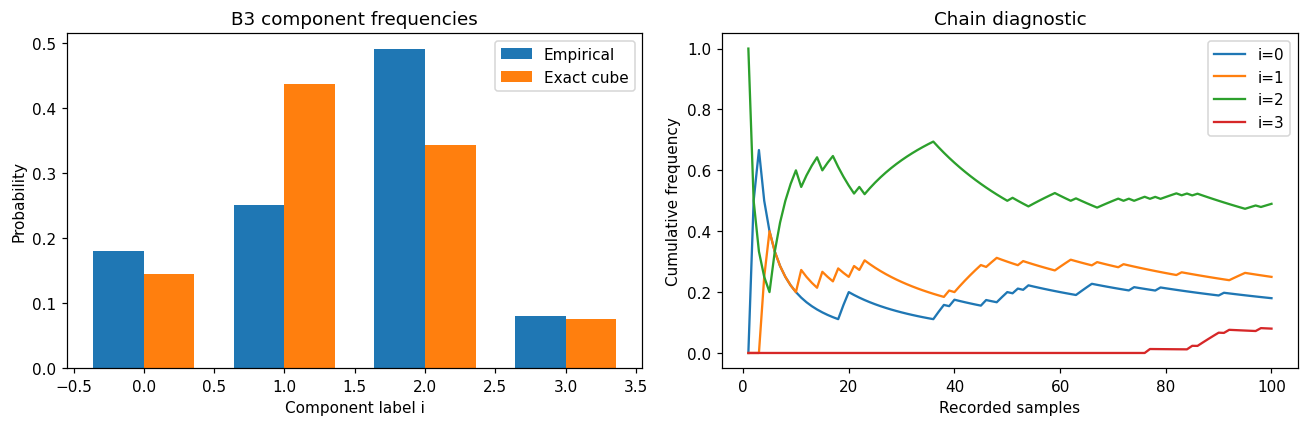

In [8]:
b2 = CubeB2(N,LAMBDA,SEED,BURN_IN,SPACING)
print(Oracle_B2(b2))
b3 = Oracle_B3(N,LAMBDA,M,SEED,BURN_IN,SPACING)
reference = exact_cube_reference(N,LAMBDA)
print("Counts:",b3['counts'])
print("Empirical vector:",b3['probabilities'])
print("Exact cube vector:",reference['probabilities'])
if plt is not None:
    fig,axes = plt.subplots(1,2,figsize=(12,4))
    labels = np.arange(N+1)
    axes[0].bar(labels-.18,b3['probabilities'],.36,label='Empirical')
    axes[0].bar(labels+.18,reference['probabilities'],.36,label='Exact cube')
    axes[0].set(xlabel='Component label i',ylabel='Probability',title='B3 component frequencies')
    axes[0].legend()
    steps = np.arange(1,M+1)
    for i in range(N+1):
        axes[1].plot(steps,np.cumsum(b3['indices']==i)/steps,label=f'i={i}')
    axes[1].set(xlabel='Recorded samples',ylabel='Cumulative frequency',title='Chain diagnostic')
    axes[1].legend()
    plt.tight_layout(); plt.show()
else:
    print('Probability charts skipped; numerical B3 results are shown above.')

## I run B1 separately
I print each phase ratio and compare my estimate against the exact cube volume. I report observed error rather than a certified confidence interval.

In [9]:
b1 = Oracle_B1(N,LAMBDA,SAMPLES,seed=SEED+10000,burn_in=BURN_IN,spacing=SPACING)
print("Alphas:",b1['alphas'])
print("Estimated volume:",b1['volume'])
print("Exact cube volume:",reference['volume'])
print("Observed relative error:",abs(b1['volume']/reference['volume']-1))

B1 phase 1/3: sampling...
  alpha_1=0.625000 (125/200)
B1 phase 2/3: sampling...
  alpha_2=0.565000 (113/200)
B1 phase 3/3: sampling...
  alpha_3=0.640000 (128/200)
Alphas: [0.625 0.565 0.64 ]
Estimated volume: 54.49914045447797
Exact cube volume: 55.03834612632515
Observed relative error: 0.009796909060631798


## I run Algorithms 2 and 3 together
I let Algorithm 3 call Algorithm 2. If the search is inconclusive, I keep that status rather than forcing an estimate.

In [10]:
start = time.perf_counter()
result = Algorithm_3(N,K,SAMPLES,THRESHOLD,SEED,BURN_IN,SPACING)
print("Status:",result['status'])
if result['mixed_volume'] is not None:
    exact = exact_mixed_volume(N,K)
    print("Chosen lambda:",result['lam'])
    print("Estimated M_k:",result['mixed_volume'])
    print("Exact cube M_k:",exact)
    print("Observed relative error:",abs(result['mixed_volume']/exact-1))
    if 'b3' in result: print("Fresh empirical vector:",result['b3']['probabilities'])
print("Elapsed seconds:",time.perf_counter()-start)

Search 1: lambda=1.31607, samples=200, p_2=0.445000
Estimating volume...
B1 phase 1/3: sampling...
  alpha_1=0.625000 (125/200)
B1 phase 2/3: sampling...
  alpha_2=0.565000 (113/200)
B1 phase 3/3: sampling...
  alpha_3=0.685000 (137/200)
Fresh component sampling...
Status: experimental_estimate
Chosen lambda: 1.3160740129524928
Estimated M_k: 5.935114397380427
Exact cube M_k: 6.283185307179585
Observed relative error: 0.05539720584102936
Fresh empirical vector: [0.13 0.35 0.39 0.13]
Elapsed seconds: 0.281950347999782


## My recorded experiment from 9 October 2026
I keep this historical result separate from the output generated by the current run. I do not date these numerical results to March.

For dimension 3, target index 2, and 2,000 samples, I obtained lambda 1.3160740129524928; phase ratios [0.574, 0.571, 0.700]; volume estimate 83.37183595125964; fresh empirical vector [0.0975, 0.3700, 0.4140, 0.1185]; mixed-volume estimate 6.642595766242438. The exact coefficient is 6.283185307179585, giving an observed relative error of 5.720%.

## What I have not achieved under the ideal-oracle assumptions

1. **Sampling:** a first chord sample from zero is not uniform over the body. I implement B2 as a Markov transition after a fixed, unproved burn-in. Repeated B2 calls must retain state. Different seeds do not prove mixing. IID concentration bounds cannot be applied directly to these chain labels.
2. **Projection:** I avoid a general QP by using cube clipping. For a general polytope, a projection near an edge/vertex may be assigned a different face by numerical error. Independent active normals must be counted by rank, not raw inequality count. For example, $(1,1,0)$ and $(1,1-\eta,0)$ project onto faces of different dimensions despite small coordinate distance.
3. **Search:** I use practical choices for the bracket, margin, threshold and refinement budget rather than a certified oracle-error protocol. Empirical acceptance is not a certified probability lower bound. I allow the search to return inconclusive. A small target probability worsens relative error when recovering a coefficient.
4. **Volume:** numerical chord endpoints, correlation, ratio fluctuations, and products of inverse estimated ratios affect B1. Ratios can be zero. Increasing the budget alone gives no proven sub-1% error guarantee.
5. **Precision:** tolerances such as $10^{-20}$ cannot generally be achieved with float64. Finite arithmetic, exponential formulas and volumes can underflow/overflow at extreme dimensions or lambda. I intend this code for moderate experiments.
6. **Complexity:** polynomial-time approximation of a convex QP is compatible with quadratic objectives. Exact minimizer/face access at constant cost is a stronger assumption. I do not establish a polynomial mixing bound or an FPRAS.
7. **Scope:** I have implemented a cube + ball prototype. I have not supplied a certified implementation for arbitrary polytopes, arbitrary convex bodies, or every target precision/confidence.

### Arithmetic work in the code
Let $q$ be the endpoint bisection count (capped at 100), $s$ the spacing, $b$ the burn-in, $m$ the recorded sample count, and $L$ the phase count.

| Routine | Approximate arithmetic work | Stored data |
|---|---|---|
| Projection / label | $O(n)$ | $O(n)$ |
| One transition | $O(nq)$ | $O(n)$ |
| B2 initialization + calls | $O((b+ms)nq)$ | $O(n)$ for the state |
| B3 | $O((b+ms)nq)$ | $O(mn)$, with diagnostic points |
| B1 | $O(L(b+ms)nq)$ | $O(mn+L)$ |
| Algorithm 2 | Sum of its B3 query costs | Histories and temporary B3 samples |
| Algorithm 3 | Algorithm 2 + B1 + fresh B3 | Combined temporary data |

I give these as arithmetic cost descriptions, not as a theorem about the work needed to achieve a specified accuracy. My actual runtime also depends on dimension, phase counts and budgets.

### How I describe this experiment
“I implemented experimental versions of the oracles and algorithms for a cube plus a Euclidean ball. I checked them against exact cube mixed volumes. The current numerical implementation does not certify the ideal-oracle assumptions or the mixing and accuracy bounds in the thesis.”

### Next experiments
I plan to repeat several seeds, compare increasing budgets, examine label autocorrelation, vary lambda and dimension, and test endpoint tolerance sensitivity. I will report each run rather than select only the lowest error. I treat general-polytope projection and reliable active-rank classification as a separate extension.

## References
I use my thesis as the source of the oracle framework and algorithms. I use the volume-computation lecture as background for the multiphase idea, not as a certificate for this implementation.

- Sourav Roy, *Approximation of Mixed Volumes of Special Convex Bodies*, master's project report, 31 March 2026, chapters 4–6. [Thesis PDF](https://github.com/Souravfrp/Souravfrp.github.io/blob/main/Mixed_volume_thesis_pdf.pdf).
- Bela Bollobas, *Volume Estimates and Rapid Mixing*, in *Flavors of Geometry*, MSRI Publications 31 (1997), Lecture 4. [Lecture PDF](https://library.slmath.org/books/Book31/files/bollobas.pdf).
- M. Dyer, A. Frieze and R. Kannan, *A Random Polynomial-Time Algorithm for Approximating the Volume of Convex Bodies*, JACM 38(1), 1991.
- R. Schneider, *Convex Bodies: The Brunn–Minkowski Theory*, second edition, 2013.

I report an experimental cube-and-ball implementation in the dimension I choose. I have not verified that the implemented oracles meet the ideal assumptions. I focus on the practical gap between ideal-oracle access and my finite numerical implementation. This notebook does not assess the thesis proofs.
